In [6]:
import numpy as np
import matplotlib.pyplot as plt

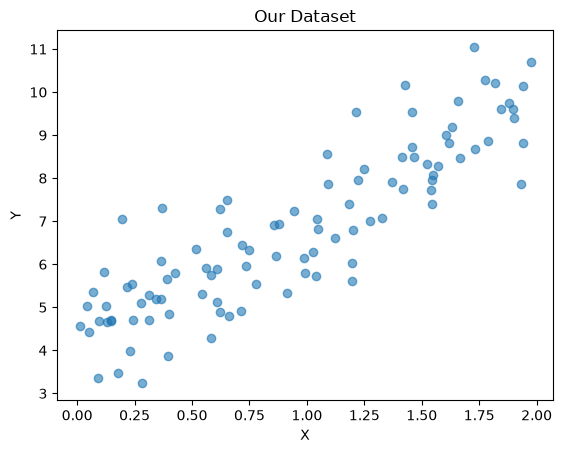

In [7]:
# Simple synthetic dataset
np.random.seed(42)
X = 2 * np.random.rand(100,1)
y = 4 + 3 * X + np.random.randn(100,1)

plt.scatter(X, y, alpha=0.6)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Our Dataset')
plt.show()


In [3]:
# implementing cost function
def compute_cost(X, y, theta0, theta1):
    m = len(y)
    predictions = theta0 + theta1 * X
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    return cost

# Testing with some values
print(compute_cost(X, y, theta0=0, theta1=0))
print(compute_cost(X,y, theta0=4, theta1=3))


25.00415182181856
0.4125533899539692


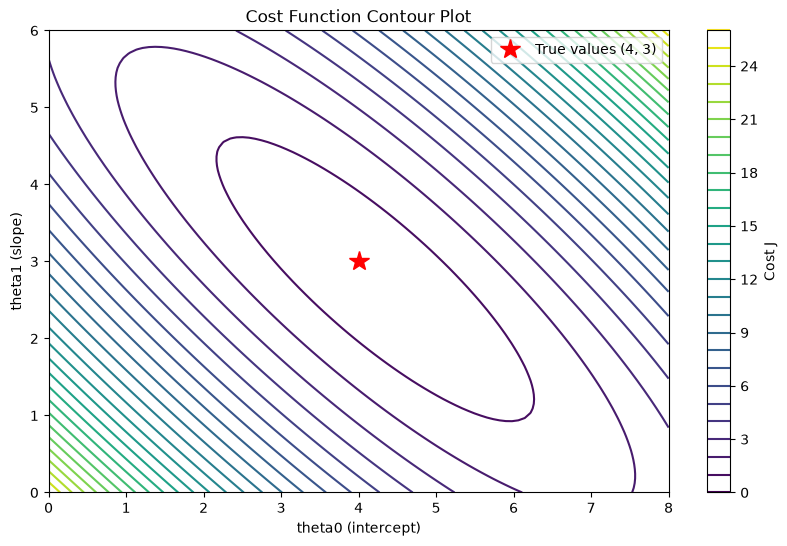

In [5]:
# visualising the cost function(contour plot)

theta0_vals = np.linspace(0, 8, 100)
theta1_vals = np.linspace(0, 6, 100)

J_vals = np.zeros((len(theta0_vals), len(theta1_vals)))

for i, t0 in enumerate(theta0_vals):
    for j, t1 in enumerate(theta1_vals):
        J_vals[i, j] = compute_cost(X, y, t0, t1)

plt.figure(figsize=(10, 6))
plt.contour(theta0_vals, theta1_vals, J_vals.T, levels=30, cmap='viridis')
plt.colorbar(label='Cost J')
plt.xlabel('theta0 (intercept)')
plt.ylabel('theta1 (slope)')
plt.title('Cost Function Contour Plot')
plt.plot(4, 3, 'r*', markersize=15, label='True values (4, 3)')
plt.legend()
plt.show()

In [6]:
# Add bias term (column of 1s) to X
X_b = np.c_[np.ones((100, 1)), X]

# Normal Equation 
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

print("theta0 (intercept):", theta_best[0])
print("theta1 (slope):", theta_best[1])

theta0 (intercept): [4.21509616]
theta1 (slope): [2.77011339]


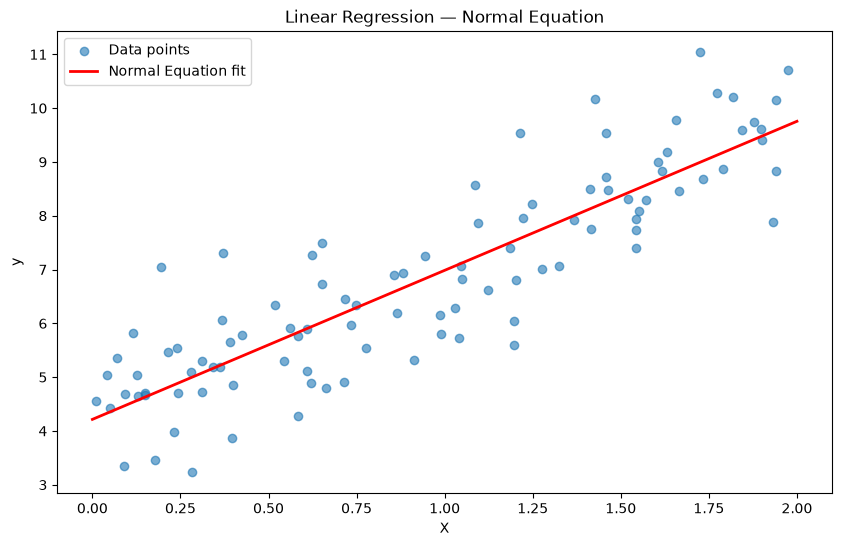

In [7]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b.dot(theta_best)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.6, label='Data points')
plt.plot(X_new, y_predict, 'r-', linewidth=2, label='Normal Equation fit')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression — Normal Equation')
plt.legend()
plt.show()

#### **Gradient Descent from Scratch:**

In [40]:

class GradientDescent:

    def __init__(self, learning_rate=0.01, epochs=1000, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.verbose = verbose
        self.verbose_every = verbose_every

        # These get set during training
        self.weights = None      # θ1, θ2, ... θn (slopes)
        self.bias = None         # θ0 (intercept)
        self.cost_history = []   # track cost per epoch
        self.weight_history = [] # track weights per epoch

    def fit(self, X, y):
        """
        X : feature matrix - shape (m, n) - m samples, n features
        y : number of features
        
        """
        m, n = X.shape
        # m = number of training examples
        # n = number of features

        # -- INITIALIZATION --
        # Random initialization of weight and bias
        self.weights = np.random.randn(n,1) * 0.01
        self.bias = np.zeros((1,1))

        # Initial shapes:
        # X.shape      → (m, n)   e.g. (100, 1) for single feature
        # y.shape      → (m, 1)   e.g. (100, 1)
        # weights.shape → (n, 1)  e.g. (1, 1) for single feature
        # bias.shape   → (1, 1)

        if self.verbose:
            print(f"Training started:")
            print(f" X shape: {X.shape}")
            print(f" y shape: {y.shape}")
            print(f" weights shape: {self.weights.shape}")
            print(f" bias shape: {self.bias.shape}")
            print(f" Initial weights: {self.weights.flatten()}")
            print(f" Initial bias: {self.bias.flatten()}")
            print()
            print("*" * 50)

        # -- Training loop --
        for epoch in range(self.epochs):

            # -- Forward Pass --
            predictions = X.dot(self.weights) + self.bias

            # errors
            errors = predictions - y

            # cost
            cost = (1/(2 * m) * np.sum(errors ** 2))
            self.cost_history.append(cost)

            # compute gradients
            dw  = (1 / m) * X.T.dot(errors)
            db = (1 / m) * np.sum(errors)

            # updating the parameters
            self.weights = self.weights - self.learning_rate * dw
            self.bias = self.bias - self.learning_rate * db

            # tracking the weight history
            self.weight_history.append({
                'epoch' : epoch,
                'weights' : self.weights.copy().flatten(),
                'bias' : self.bias.copy().flatten()[0],
                'cost' : cost
            })

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs}")
                print (f"Cost: {cost:.6f}")
                print (f"Weights: {self.weights.flatten()}")
                print (f"Bias: {self.bias.flatten()[0]:.4f}")
                print()

        if self.verbose:
            print("-" * 50)
            print(f"Training complete!")
            print(f"  Final weights: {self.weights.flatten()}")
            print(f"  Final bias: {self.bias.flatten()[0]:.4f}")

        return self

    def predict(self, X):
        return X.dot(self.weights) + self.bias

    def score(self, X, y):
        predictions = self.predict(X)
        ss_res = np.sum((y - predictions) ** 2)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_res / ss_total)

    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'b-')
        plt.xlabel('Epoch')
        plt.ylabel('Cost (MSE)')
        plt.title('Cost history')
        plt.grid(True)
        plt.show()

    def plot_weight_evolution(self, true_weights=None, true_bias=None):
        epochs = [h['epoch'] for h in self.weight_history]
        biases = [h['bias'] for h in self.weight_history]
        
        n_weights = len(self.weight_history[0]['weights'])
        
        # Plot each weight separately
        fig, axes = plt.subplots(2, (n_weights + 1) // 2 + 1, 
                                  figsize=(18, 8))
        axes = axes.flatten()
        
        for i in range(n_weights):
            weights_i = [h['weights'][i] for h in self.weight_history]
            axes[i].plot(epochs, weights_i, 'r-')
            axes[i].set_title(f'Weight {i+1} (θ{i+1})')
            axes[i].set_xlabel('Epoch')
            axes[i].set_ylabel(f'θ{i+1}')
            axes[i].grid(True)
            
            # Only plot true value if provided
            if true_weights is not None:
                axes[i].axhline(y=true_weights[i], color='g', 
                               linestyle='--', 
                               label=f'Sklearn value ({true_weights[i]:.2f})')
                axes[i].legend(fontsize=7)
        
        # Plot bias separately
        axes[n_weights].plot(epochs, biases, 'b-')
        axes[n_weights].set_title('Bias (θ0)')
        axes[n_weights].set_xlabel('Epoch')
        axes[n_weights].set_ylabel('θ0')
        axes[n_weights].grid(True)
        
        if true_bias is not None:
            axes[n_weights].axhline(y=true_bias, color='g', 
                                   linestyle='--',
                                   label=f'Sklearn value ({true_bias:.2f})')
            axes[n_weights].legend(fontsize=7)
        
        # Hide empty subplots
        for j in range(n_weights + 1, len(axes)):
            axes[j].set_visible(False)
        
        plt.suptitle('Weight Evolution During Training', fontsize=14)
        plt.tight_layout()
        plt.show()

In [29]:
model = GradientDescent(0.1, 100, True, 100)
model.fit(X,y)

Training started:
 X shape: (100, 1)
 y shape: (100, 1)
  weights shape: (1, 1)
  bias shape: (1, 1)
  Initial weights: [-0.01070892]
  Initial bias: [0.]
**************************************************
Epoch    0/100 | Cost: 25.083298 | Weights: [0.72902161] | Bias: 0.6830
--------------------------------------------------
Training complete!
  Final weights: [2.92776429]
  Final bias: 4.0365


In [30]:
model.score(X,y)

np.float64(0.7665192775779848)

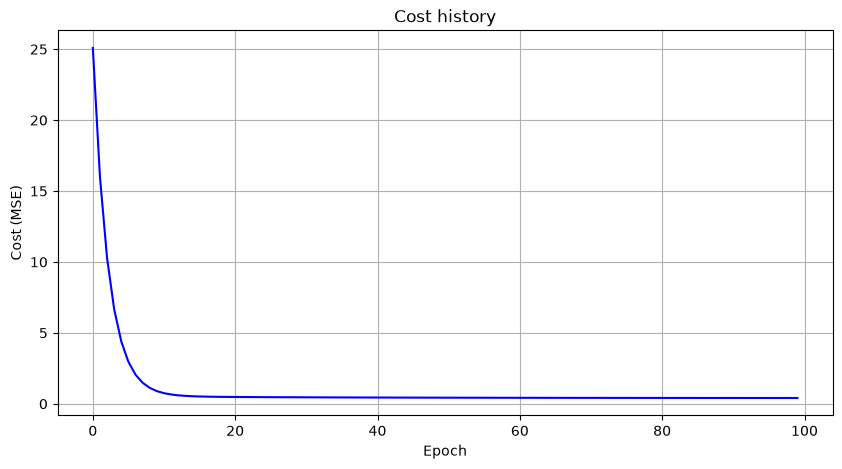

In [31]:
model.plot_cost_history()

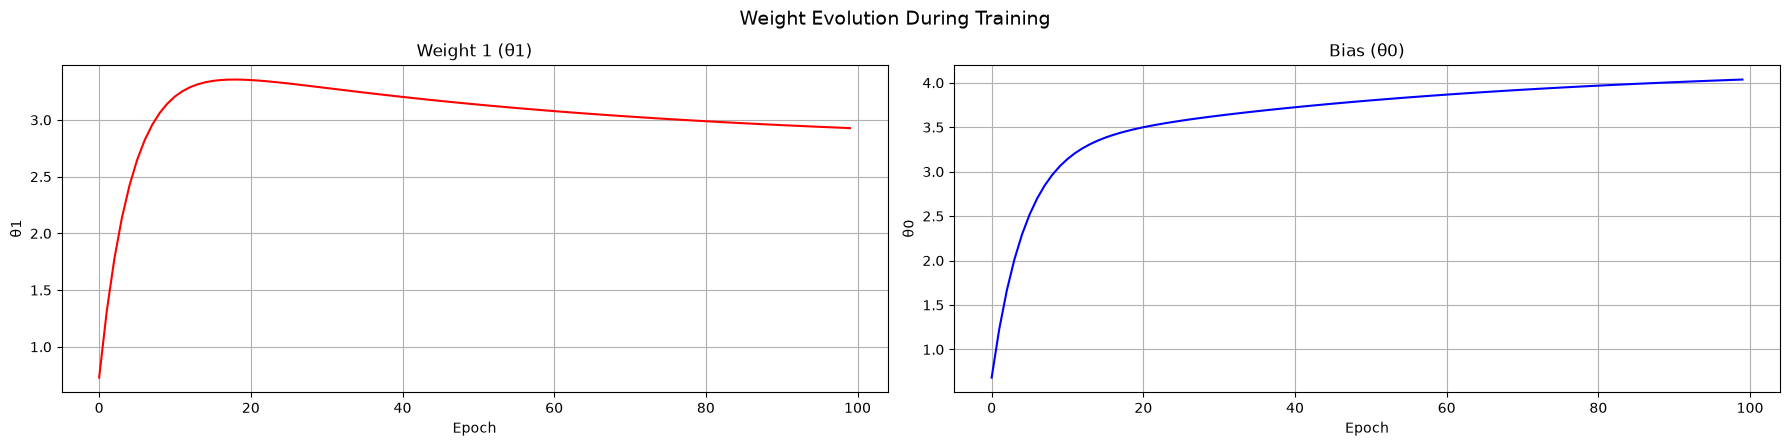

In [32]:
model.plot_weight_evolution()

#### **Now let's generate a 10-feature dataset and run everything again**

In [33]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Generate dataset with 10 features
X_multi, y_multi = make_regression(
    n_samples=500,
    n_features=10,
    noise=10,
    random_state=42
)

# Reshape y to column vector
y_multi = y_multi.reshape(-1, 1)

print("X_multi shape:", X_multi.shape)
print("y_multi shape:", y_multi.shape)

X_multi shape: (500, 10)
y_multi shape: (500, 1)


In [34]:
scaler = StandardScaler()
X_multi_scaled = scaler.fit_transform(X_multi)

print("Mean after scaling:", X_multi_scaled.mean(axis=0).round(4))
print("Std after scaling:", X_multi_scaled.std(axis=0).round(4))

Mean after scaling: [-0.  0.  0. -0. -0.  0.  0. -0.  0. -0.]
Std after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [36]:
sk_model = LinearRegression()
sk_model.fit(X_multi_scaled, y_multi)

print("Sklearn coefficients:", sk_model.coef_.flatten().round(4))
print("Sklearn intercept:", sk_model.intercept_[0].round(4))
print("Sklearn R²:", sk_model.score(X_multi_scaled, y_multi))

Sklearn coefficients: [39.455  63.9095 19.855  46.9219 24.4365 15.706  82.9567 66.832   7.1515
 28.5014]
Sklearn intercept: -1.587
Sklearn R²: 0.9956312742196273


In [48]:
gd_model = GradientDescent(
    learning_rate=0.01,
    epochs=500,
    verbose=True,
    verbose_every=100
)

gd_model.fit(X_multi_scaled, y_multi)

Training started:
 X shape: (500, 10)
 y shape: (500, 1)
 weights shape: (10, 1)
 bias shape: (1, 1)
 Initial weights: [ 0.00865755 -0.01200296 -0.00334501 -0.00474945 -0.00653329  0.01765454
  0.00404982 -0.01260884  0.00917862  0.02122156]
 Initial bias: [0.]

**************************************************
Epoch    0/500
Cost: 10561.262053
Weights: [0.46174111 0.55267259 0.18474206 0.43076776 0.27181586 0.12760385
 0.8707274  0.63783195 0.04932912 0.30038187]
Bias: -0.0159

Epoch  100/500
Cost: 1490.553796
Weights: [27.32080055 37.88945381 12.07187615 28.70028594 16.8518278   8.33896255
 54.19649769 41.76939956  3.20047764 17.84289061]
Bias: -1.0119

Epoch  200/500
Cost: 250.671178
Weights: [35.81299254 53.25978296 16.63519715 39.82508477 22.14316092 12.42756996
 72.84884092 57.22320296  5.05857555 24.38625685]
Bias: -1.3765

Epoch  300/500
Cost: 75.995358
Weights: [38.43268187 59.55693665 18.47471469 44.16813775 23.78662656 14.29794178
 79.39246136 63.10489932  6.09020945 26.884

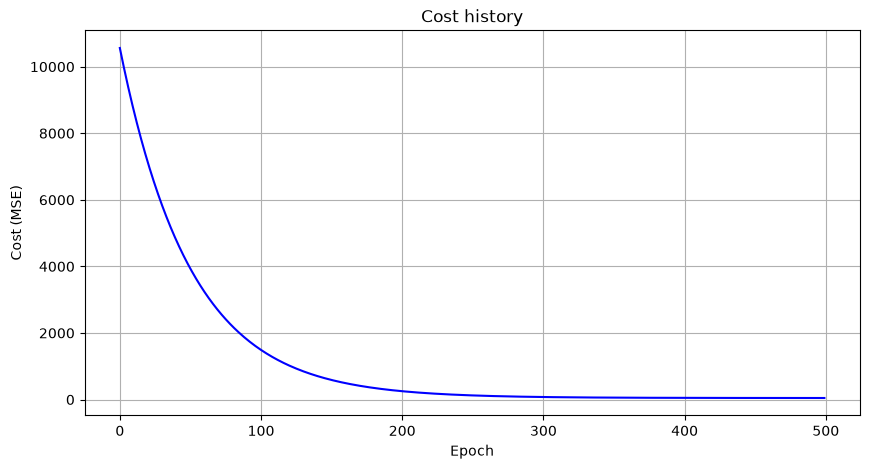

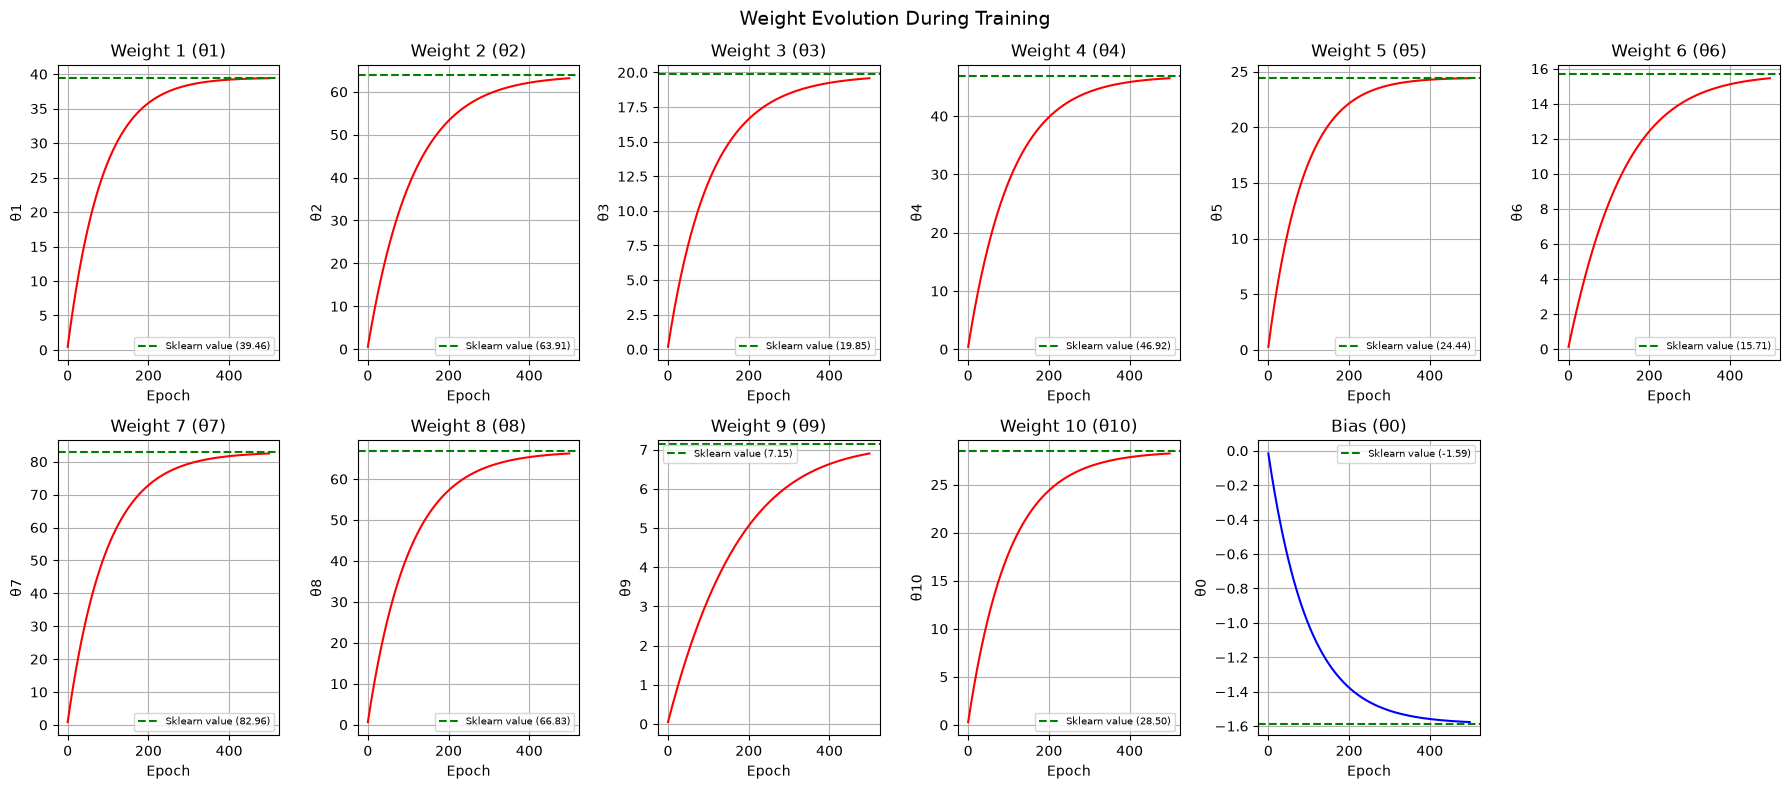

In [49]:
gd_model.plot_cost_history()
gd_model.plot_weight_evolution(
    true_weights=sk_model.coef_.flatten(),
    true_bias=sk_model.intercept_[0]
)

In [51]:
print("Sklearn weights:        ", sk_model.coef_.flatten().round(4))
print("Gradient Descent weights:", gd_model.weights.flatten().round(4))
print()
print("Sklearn bias:        ", round(sk_model.intercept_[0], 4))
print("Gradient Descent bias:", round(gd_model.bias[0][0], 4))
print()
print("Sklearn R²:          ", round(sk_model.score(X_multi_scaled, y_multi), 4))
print("Gradient Descent R²: ", round(gd_model.score(X_multi_scaled, y_multi), 4))

Sklearn weights:         [39.455  63.9095 19.855  46.9219 24.4365 15.706  82.9567 66.832   7.1515
 28.5014]
Gradient Descent weights: [39.4145 63.1753 19.5816 46.5045 24.408  15.4593 82.5038 66.2479  6.9019
 28.2385]

Sklearn bias:         -1.587
Gradient Descent bias: -1.5765

Sklearn R²:           0.9956
Gradient Descent R²:  0.9956
